# 07 — CO (CSF) retrieval error via Monte-Carlo parameter sampling

Propagates injection-pressure, fire-centroid, and analyst-choice uncertainty through the Cross-Sectional Flux CO retrieval (the AER_LH wind variant — the manuscript headline CO number).

**Reported as a single combined distribution** (median + 95% CI). Per-member inputs are logged for the tornado / variance decomposition. See `src/error_estimation.py` for the design notes.

In [1]:
# ── Monte-Carlo error-estimation parameters (sampled ranges agreed in brainstorm) ─
N_SAMPLES: int = 500
SEED: int      = 42

FIRE_DATE  = "2026-01-18"
TARGET_DAY = "".join(FIRE_DATE.split("-")[1:])  # "0118"

# Analyst-choice sample ranges
AI_THRESHOLDS    = [2.0]   # discrete; also selects the pressure KDE
QA_LEVELS_UINT8  = [50]                        # qa_value cut (loader uses uint8 0-100)

# Injection-pressure KDE (matched AER_LH pixels)
PRESS_RADIUS_KM    = 450.0
PRESS_MIN_PIXELS   = 15

# Centroid KDE (FRP-weighted MODIS), recentered on the retrieval centroid
CENTROID_LOCAL_RADIUS_KM = 200.0
CENTROID_MIN_CONF        = 75
CENTROID_SAT             = "Aqua"
CENTROID_DAYNIGHT        = "D"

# Fail-loud control: raised from 0.25 to accommodate the alignment gate, which
# intentionally rejects ~30–45% of members on physical grounds.
MAX_FAIL_FRACTION = 0.50

# CO-specific ranges
BG_START_RANGE   = (-350.0, -250.0)   # far-upwind window start (km)
BG_WIDTH_RANGE   = (80.0, 120.0)      # window width (km)
THW_RANGE        = (75.0, 150.0)      # transect half-width (km)
NTRANSECT_CHOICES = list(range(8, 15))
# CO grid (Griffin et al. 2024): 4 km cells at the fire latitude, Adams et al.
# (2019) oversampling with a 7 km radius (src/oversampling.py). Kept as a
# one-element choice list so the RNG draw sequence is unchanged.
GRID_CHOICES_KM  = [4.0]
OVERSAMPLE_RADIUS_KM = 7.0
# A transect is accepted only if MORE THAN this fraction of its samples have a
# finite ΔCO (sampled half-width 75–150 km -> 38–76 samples at 4 km spacing).
MIN_VALID_FRACTION = 0.5
MIN_BG_PIXELS    = 10
OUT_DIR = None  # set after ROOT is known

# ── Plume-alignment gate ──────────────────────────────────────────────────────
# Parameters (PCA radius, far-field distance, 15° threshold, minimum pixel counts)
# live in config/mc_alignment_gate.yaml and are loaded below with the gate code
# (src.error_estimation.plume_axis_pca / angular_diff_deg), shared with the other MC notebook.

In [2]:
import sys, glob, warnings
from pathlib import Path
from collections import defaultdict
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import shapely
warnings.filterwarnings("ignore")  # KDE/curve_fit chatter; failures are still raised explicitly

ROOT = Path(".").resolve()
while not ((ROOT / "src").exists() and (ROOT / "data").exists()):
    if ROOT == ROOT.parent:
        raise RuntimeError("Could not locate project root (need src/ and data/).")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src import error_estimation as ee
from src import plume_helpers as ph
from src.data_helpers import (load_co_l2, load_no2_l2, load_aer_ai,
                              load_aer_lh, get_modis_hotspot)

DATA = ROOT / "data"
ERA5_PL = DATA / "ERA5_winds_pressure_levels.nc"
MODIS_CSV = DATA / "fire_nrt_M-C61_723973.csv"
HOTSPOT_CSV = DATA / "daily_dominant_hotspot_summary.csv"
QA_BASE = 50

# Wide loader domain (matches the science notebooks)
LAT_MIN, LAT_MAX = -66.83, -6.83
LON_MIN, LON_MAX = -103.05, -43.05

modis = get_modis_hotspot(HOTSPOT_CSV, FIRE_DATE,
                          lat_min=LAT_MIN, lat_max=LAT_MAX, lon_min=LON_MIN, lon_max=LON_MAX)
FIRE_LAT = float(modis["dominant_lat"].values[0])
FIRE_LON = float(modis["dominant_lon"].values[0])
print(f"Retrieval centroid: ({FIRE_LAT:.4f}, {FIRE_LON:.4f})  FRP={modis['dominant_frp_mw'].values[0]} MW")

def _load_and_concat(paths, loader, **kwargs):
    chunks, scal = defaultdict(list), {}
    for p in paths:
        d = loader(Path(p), **kwargs)
        if d is None:
            continue
        for k, v in d.items():
            (chunks[k].append(v) if isinstance(v, np.ndarray) else scal.__setitem__(k, v))
    out = {k: np.concatenate(v) for k, v in chunks.items()}; out.update(scal)
    return out

roi_kwargs = dict(lat_min=LAT_MIN, lat_max=LAT_MAX, lon_min=LON_MIN, lon_max=LON_MAX, qa_threshold=QA_BASE)
ai_base = _load_and_concat(
    sorted(glob.glob(str(DATA/TARGET_DAY/"S5P_OFFL_L2__AER_AI_2026*"))), load_aer_ai, **roi_kwargs)

# ── Plume boundary: clip AI outside the saved blob-clustered inclusion
# geometry down below threshold, replacing the previous ad hoc "lon > -72"
# clip. Reused below for the AER_AI grid too (ai_flat in the grid-precompute
# cell) so the plume mask is boundary-consistent for every MC member.
PLUME_BOUNDARY_PATH = DATA / TARGET_DAY / "plume_boundary.geojson"
plume_boundary = ph.load_plume_boundary(PLUME_BOUNDARY_PATH)
AI_THRESHOLD_BOUNDARY = plume_boundary.threshold
_in_boundary = shapely.contains_xy(plume_boundary.boundary, ai_base["lon"], ai_base["lat"])
ai_base["ai"] = np.where(_in_boundary, ai_base["ai"],
                         np.minimum(ai_base["ai"], AI_THRESHOLD_BOUNDARY - 1e-3))
print(f"Plume boundary: {plume_boundary.boundary.geom_type}  threshold={AI_THRESHOLD_BOUNDARY:.3f}  "
      f"({int(_in_boundary.sum())}/{_in_boundary.size} AER_AI pixels inside boundary)")
assert len(AI_THRESHOLDS) == 1 and abs(AI_THRESHOLDS[0] - AI_THRESHOLD_BOUNDARY) < 1e-6, (
    f"AI_THRESHOLDS={AI_THRESHOLDS} no longer matches the boundary threshold "
    f"{AI_THRESHOLD_BOUNDARY} — update AI_THRESHOLDS or re-check the boundary file."
)

alh_base = _load_and_concat(
    sorted(glob.glob(str(DATA/TARGET_DAY/"S5P_OFFL_L2__AER_LH_2026*"))), load_aer_lh, **roi_kwargs)

# ── Injection-pressure KDE per AI threshold (so AI threshold is a live parameter) ─
pressure_kdes = {}
for thr in AI_THRESHOLDS:
    try:
        pk = ee.build_pressure_kde(ai_base["ai"], ai_base["lat"], ai_base["lon"],
                                   alh_base["alh_pres"], alh_base["lat"], alh_base["lon"],
                                   FIRE_LAT, FIRE_LON, ai_threshold=thr,
                                   radius_km=PRESS_RADIUS_KM, min_pixels=PRESS_MIN_PIXELS)
        pressure_kdes[thr] = pk
    except ValueError as e:
        print(f"  AI thr {thr}: pressure KDE skipped ({e})")
AVAILABLE_AI = sorted(pressure_kdes)
assert AVAILABLE_AI, "No AI threshold yielded a valid pressure KDE."
print(f"AI thresholds with a pressure KDE: {AVAILABLE_AI}")
for thr in AVAILABLE_AI:
    pk = pressure_kdes[thr]
    print(f"  thr {thr}: n={pk['n']:3d}  median={pk['median_hpa']:.0f} hPa  IQR={pk['iqr_hpa']:.0f}")

# ── Centroid KDE (recentered on the retrieval centroid, keep KDE spread) ──────
ck = ee.build_centroid_kde(MODIS_CSV, FIRE_DATE, FIRE_LAT, FIRE_LON,
                           local_radius_km=CENTROID_LOCAL_RADIUS_KM,
                           min_confidence=CENTROID_MIN_CONF,
                           satellite=CENTROID_SAT, daynight=CENTROID_DAYNIGHT)
_cs = ck["kde"].resample(5000, seed=SEED)
CENTROID_DLAT = FIRE_LAT - float(_cs[0].mean())
CENTROID_DLON = FIRE_LON - float(_cs[1].mean())
print(f"Centroid KDE: n={ck['n']}, recenter shift = ({CENTROID_DLAT:+.3f}, {CENTROID_DLON:+.3f})")

# ── ERA5 pressure-level wind slice at overpass ───────────────────────────────
# TROPOMI ascending-node crossing is 13:30 local solar time -> UTC = 13.5 - lon/15
OVERPASS = pd.Timestamp(FIRE_DATE) + pd.Timedelta(hours=13.5 - FIRE_LON/15.0)
era5 = ee.load_era5_pl_slice(ERA5_PL, OVERPASS)
print(f"ERA5 slice: {era5.selected_time}  ({len(era5.p_sorted)} levels)")

Retrieval centroid: (-37.5484, -72.5545)  FRP=953.6838 MW
Plume boundary: MultiPolygon  threshold=2.000  (2764/1050159 AER_AI pixels inside boundary)


AI thresholds with a pressure KDE: [2.0]
  thr 2.0: n= 99  median=898 hPa  IQR=73
Centroid KDE: n=146, recenter shift = (-0.491, +0.196)


ERA5 slice: 2026-01-18 18:00:00  (13 levels)


In [3]:
# ── Pre-filter plume pixels for per-member PCA ───────────────────────────────
# Keep only pixels above the AI threshold once — the plume-boundary clip is
# already applied to ai_base (see the loading cell above), so out-of-boundary
# pixels are excluded automatically.
# Per-member PCA then only needs to compute distances within this small set.
_pca_pre = ai_base["ai"] > min(AI_THRESHOLDS)
PLUME_LAT_PCA = ai_base["lat"][_pca_pre]
PLUME_LON_PCA = ai_base["lon"][_pca_pre]
PLUME_AI_PCA  = ai_base["ai"][_pca_pre]
print(f"Pre-filtered plume pixels for per-member PCA: {_pca_pre.sum():,}  (AI > {min(AI_THRESHOLDS)})")

# ── Plume-alignment gate: shared implementation + config ─────────────────────
GATE = ee.load_alignment_gate_config(ROOT / "config" / "mc_alignment_gate.yaml")
PCA_RADIUS_KM            = GATE["pca_radius_km"]
FAR_FIELD_MIN_KM         = GATE["far_field_min_km"]
MAX_WIND_PLUME_ANGLE_DEG = GATE["max_wind_plume_angle_deg"]
GATE_PCA_KW = dict(radius_km=PCA_RADIUS_KM, far_field_min_km=FAR_FIELD_MIN_KM,
                   min_pixels=GATE["min_pca_pixels"], min_far_pixels=GATE["min_far_field_pixels"])
print(f"Alignment gate: {GATE}")

Pre-filtered plume pixels for per-member PCA: 2,096  (AI > 2.0)
Alignment gate: {'pca_radius_km': 450.0, 'far_field_min_km': 150.0, 'max_wind_plume_angle_deg': 15.0, 'min_pca_pixels': 20, 'min_far_field_pixels': 3}


In [4]:
# ── Central retrieval value from the canonical notebook 02 results ───
_RETR_DIR = ROOT / "outputs" / "retrievals" / "0118"
_co_res = pd.read_csv(_RETR_DIR / "co_retrieval.csv", index_col=0)["value"]
CO_REF_KGS = float(_co_res["co_flux_variant_kg_s"])   # nb02 AER_LH variant (preferred)
print(f"Central CO retrieval (nb02): {CO_REF_KGS:.1f} kg/s")

Central CO retrieval (nb02): 1363.3 kg/s


In [5]:
# ── Load CO L2 (all orbits) and AER_AI at both QA levels; precompute grids ────
def _load_co_concat(qa):
    return _load_and_concat(
        sorted(glob.glob(str(DATA/TARGET_DAY/"S5P_OFFL_L2__CO_____*.nc"))),
        load_co_l2, lat_min=LAT_MIN, lat_max=LAT_MAX,
        lon_min=LON_MIN, lon_max=LON_MAX, qa_threshold=qa, with_corners=True,
    )

def _load_ai_concat_boundary(qa):
    """AER_AI, all overpasses, clipped to the same plume boundary as ai_base."""
    a = _load_and_concat(
        sorted(glob.glob(str(DATA/TARGET_DAY/"S5P_OFFL_L2__AER_AI_2026*"))),
        load_aer_ai, lat_min=LAT_MIN, lat_max=LAT_MAX,
        lon_min=LON_MIN, lon_max=LON_MAX, qa_threshold=qa, with_corners=True,
    )
    in_b = shapely.contains_xy(plume_boundary.boundary, a["lon"], a["lat"])
    a["ai"] = np.where(in_b, a["ai"], np.minimum(a["ai"], AI_THRESHOLD_BOUNDARY - 1e-3))
    return a

OUT_DIR = ROOT / "outputs" / "error_mc" / TARGET_DAY
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Precompute (qa, cell_km) -> (lat, lon, co_g, ai_g) on the 4 km oversampled grid
# (same grid definition as nb02: cells of cell_km at the retrieval centroid latitude).
# The grid is centroid-independent.
from src.oversampling import regular_grid_km
grids = {}
for qa in QA_LEVELS_UINT8:
    co_flat = _load_co_concat(qa)
    ai_flat = _load_ai_concat_boundary(qa)
    for g in GRID_CHOICES_KM:
        _spec = regular_grid_km(LAT_MIN, LAT_MAX, LON_MIN, LON_MAX, cell_km=g, ref_lat=FIRE_LAT)
        lat, lon, co_g, ai_g, _diag = ee.oversample_co_ai_grid(co_flat, ai_flat, _spec,
                                                               OVERSAMPLE_RADIUS_KM)
        grids[(qa, g)] = (lat, lon, co_g, ai_g)
        print(f"qa={qa}, {g} km: grid {co_g.shape}, CO cells={int(np.isfinite(co_g).sum()):,}, "
              f"oversampling CO {_diag['co']['n_points']:,} pts / AI {_diag['ai']['n_points']:,} pts")
print(f"Total precomputed grids: {len(grids)}")

qa=50, 4.0 km: grid (1669, 1323), CO cells=1,353,823, oversampling CO 1,086,788 pts / AI 2,380,110 pts
Total precomputed grids: 1


In [6]:
# ── Draw the parameter samples (one row per member) ──────────────────────────
rng = np.random.default_rng(SEED)

# AI threshold (discrete, among those with a valid pressure KDE)
samp_ai = rng.choice(AVAILABLE_AI, size=N_SAMPLES)

# Injection pressure: sample from the AI-threshold-matched KDE, clip to ERA5 range
p_lo, p_hi = float(era5.p_sorted.min()), float(era5.p_sorted.max())
samp_pressure = np.empty(N_SAMPLES)
for thr in AVAILABLE_AI:
    m = samp_ai == thr
    if m.any():
        draw = pressure_kdes[thr]["kde"].resample(int(m.sum()), seed=int(rng.integers(1e9))).flatten()
        samp_pressure[m] = np.clip(draw, p_lo, p_hi)

# Centroid: recentered KDE draws
_cdraw = ck["kde"].resample(N_SAMPLES, seed=SEED + 1)
samp_lat = _cdraw[0] + CENTROID_DLAT
samp_lon = _cdraw[1] + CENTROID_DLON

# QA level
samp_qa = rng.choice(QA_LEVELS_UINT8, size=N_SAMPLES)

# CO analyst-choice draws
samp_grid   = rng.choice(GRID_CHOICES_KM, size=N_SAMPLES)
samp_bgstart = rng.uniform(*BG_START_RANGE, size=N_SAMPLES)
samp_bgwidth = rng.uniform(*BG_WIDTH_RANGE, size=N_SAMPLES)
samp_thw    = rng.uniform(*THW_RANGE, size=N_SAMPLES)
samp_nt     = rng.choice(NTRANSECT_CHOICES, size=N_SAMPLES)
print(f"Drew {N_SAMPLES} parameter sets.")

Drew 500 parameter sets.


In [7]:
# ── Monte-Carlo loop ─────────────────────────────────────────────────────────
records, fails = [], []
for i in range(N_SAMPLES):
    lat, lon, co_g, ai_g = grids[(int(samp_qa[i]), float(samp_grid[i]))]
    u, v, spd, theta = ee.wind_from_pressure(era5, float(samp_lat[i]), float(samp_lon[i]), float(samp_pressure[i]))
    bg_min = float(samp_bgstart[i]); bg_max = bg_min + float(samp_bgwidth[i])
    row = dict(member=i, pressure_hpa=float(samp_pressure[i]),
               fire_lat=float(samp_lat[i]), fire_lon=float(samp_lon[i]),
               ai_threshold=float(samp_ai[i]), qa=int(samp_qa[i]), grid_km=float(samp_grid[i]),
               bg_x_min_km=bg_min, bg_width_km=float(samp_bgwidth[i]),
               transect_half_width_km=float(samp_thw[i]), n_transects=int(samp_nt[i]),
               wind_speed=spd)
    try:
        # ── Plume-alignment gate ──────────────────────────────────────────────
        # PCA is recomputed at the sampled centroid so the pixel set reflects
        # the centroid draw, not the canonical fire location.
        theta_plume = ee.plume_axis_pca(float(samp_lat[i]), float(samp_lon[i]),
                                          PLUME_LAT_PCA, PLUME_LON_PCA, PLUME_AI_PCA, **GATE_PCA_KW)
        delta_theta = ee.angular_diff_deg(theta, theta_plume)
        row["theta_wind_deg"]  = float(np.degrees(theta))
        row["theta_plume_deg"] = float(np.degrees(theta_plume))
        row["delta_theta_deg"] = delta_theta
        if delta_theta > MAX_WIND_PLUME_ANGLE_DEG:
            raise ValueError(
                f"Wind/plume misalignment: Δθ={delta_theta:.1f}° > "
                f"{MAX_WIND_PLUME_ANGLE_DEG}°  "
                f"(θ_wind={np.degrees(theta):.1f}°, "
                f"θ_plume={np.degrees(theta_plume):.1f}°, "
                f"p={float(samp_pressure[i]):.0f} hPa)"
            )
        # ── CSF retrieval ─────────────────────────────────────────────────────
        r = ee.co_flux_member(lat, lon, co_g, ai_g, u, v, theta,
                              ai_threshold=float(samp_ai[i]),
                              bg_x_min_km=bg_min, bg_x_max_km=bg_max,
                              n_transects=int(samp_nt[i]), transect_half_width_km=float(samp_thw[i]),
                              min_bg_pixels=MIN_BG_PIXELS, min_valid_fraction=MIN_VALID_FRACTION,
                              sample_spacing_m=float(samp_grid[i]) * 1e3)
        row.update(r); records.append(row)
    except (ValueError, RuntimeError) as e:
        row["error"] = str(e); fails.append(row)

df = pd.DataFrame(records)
fail_frac = len(fails) / N_SAMPLES
print(f"Converged: {len(df)}/{N_SAMPLES}  (failures: {len(fails)}, {fail_frac:.1%})")
if fails:
    fail_df = pd.DataFrame(fails)
    n_align = fail_df["error"].str.contains("misalignment", na=False).sum()
    n_pca   = fail_df["error"].str.contains("PCA:", na=False).sum()
    n_csf   = len(fails) - n_align - n_pca
    print(f"  alignment gate : {n_align} ({n_align/N_SAMPLES:.1%})")
    print(f"  PCA failure    : {n_pca}")
    print(f"  CSF failure    : {n_csf}")
assert fail_frac <= MAX_FAIL_FRACTION, (
    f"Failure fraction {fail_frac:.1%} exceeds MAX_FAIL_FRACTION={MAX_FAIL_FRACTION:.0%}; "
    "inspect `fails` before trusting the distribution.")

Converged: 287/500  (failures: 213, 42.6%)
  alignment gate : 213 (42.6%)
  PCA failure    : 0
  CSF failure    : 0


In [8]:
# ── Combined distribution summary ────────────────────────────────────────────
summ = ee.summarize(df["flux_kgs"].to_numpy(), "CO flux", "kg/s")
print("CO flux (CSF, AER_LH wind) — combined Monte-Carlo distribution")
print(f"  median   : {summ['median']:.1f} kg/s")
print(f"  95% CI   : [{summ['p2_5']:.1f}, {summ['p97_5']:.1f}] kg/s")
print(f"  rel. err : ±{summ['rel_err_pct']:.1f}%   (n={summ['n']})")
print(f"  t/day    : {summ['median']*86.4:.0f}  [{summ['p2_5']*86.4:.0f}, {summ['p97_5']*86.4:.0f}]")
print(f"\nReference (nb02 AER_LH variant): {CO_REF_KGS:.1f} kg/s")

CO flux (CSF, AER_LH wind) — combined Monte-Carlo distribution
  median   : 1273.3 kg/s
  95% CI   : [675.6, 1842.7] kg/s
  rel. err : ±45.8%   (n=287)
  t/day    : 110017  [58369, 159209]

Reference (nb02 AER_LH variant): 1363.3 kg/s


In [9]:
# ── Export canonical CO flux distribution (consumed by 09) ──────────
_RETR_DIR = ROOT / "outputs" / "retrievals" / "0118"
_RETR_DIR.mkdir(parents=True, exist_ok=True)
_v = df["flux_kgs"].to_numpy(); _v = _v[np.isfinite(_v)]
_dist = {
    "species": "CO", "units": "kg/s", "n": int(_v.size),
    "mean": float(_v.mean()), "std": float(_v.std()), "median": float(np.median(_v)),
    "p16": float(np.percentile(_v, 16)), "p84": float(np.percentile(_v, 84)),
    "p2_5": float(np.percentile(_v, 2.5)), "p97_5": float(np.percentile(_v, 97.5)),
}
pd.Series(_dist).to_csv(_RETR_DIR / "co_distribution.csv", header=["value"])
print(f"Wrote co_distribution.csv: mean={_dist['mean']:.1f}+/-{_dist['std']:.1f} kg/s, "
      f"median={_dist['median']:.1f}, 1sigma[p16,p84]=[{_dist['p16']:.1f},{_dist['p84']:.1f}]")

Wrote co_distribution.csv: mean=1257.6+/-323.6 kg/s, median=1273.3, 1sigma[p16,p84]=[941.2,1557.0]


In [10]:
# ── Tornado / variance decomposition ─────────────────────────────────────────
input_cols = ["pressure_hpa", "fire_lat", "fire_lon", "ai_threshold", "qa",
              "grid_km", "bg_x_min_km", "bg_width_km", "transect_half_width_km", "n_transects"]
tor = ee.tornado_sensitivity(df[input_cols], df["flux_kgs"].to_numpy(), "CO flux")
print(tor.to_string(index=False))

             parameter  spearman  std_beta  abs_std_beta  var_share_pct
          pressure_hpa  0.380634  0.353543      0.353543      57.116138
transect_half_width_km  0.230699  0.227980      0.227980      23.750235
              fire_lon -0.107429 -0.164903      0.164903      12.426032
           n_transects -0.101855 -0.094448      0.094448       4.076230
           bg_width_km -0.070293 -0.056156      0.056156       1.440987
              fire_lat -0.053748 -0.044906      0.044906       0.921467
           bg_x_min_km -0.010465 -0.024259      0.024259       0.268911


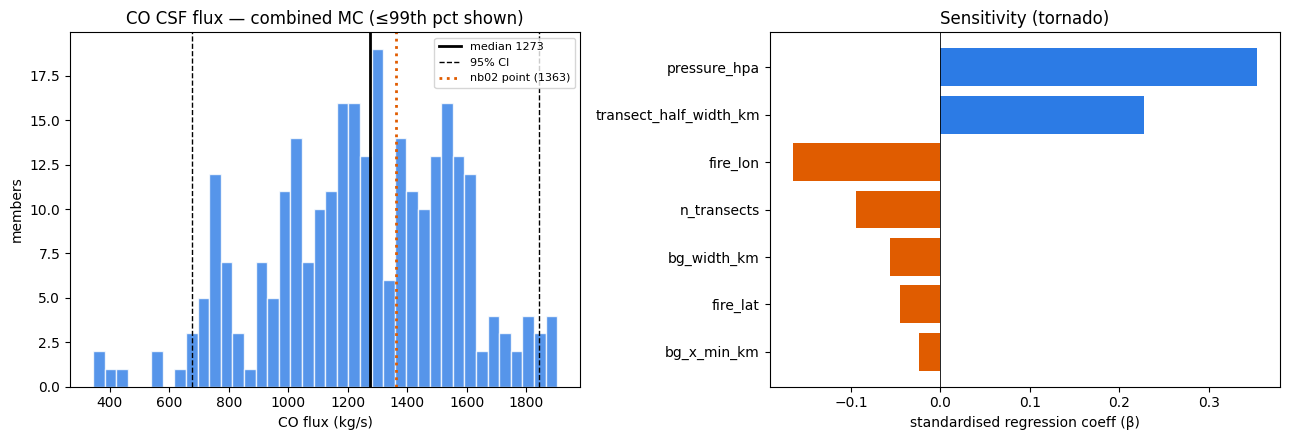

Saved: /Users/maperezc/Downloads/wildfires/outputs/error_mc/0118/co_error_mc.png


In [11]:
# ── Figures: distribution + tornado ──────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
q99 = np.percentile(df["flux_kgs"], 99)
ax.hist(df["flux_kgs"][df["flux_kgs"] <= q99], bins=40, color="#2c7be5", alpha=0.8, edgecolor="white")
ax.axvline(summ["median"], color="k", lw=2, label=f"median {summ['median']:.0f}")
ax.axvline(summ["p2_5"], color="k", ls="--", lw=1)
ax.axvline(summ["p97_5"], color="k", ls="--", lw=1, label="95% CI")
ax.axvline(CO_REF_KGS, color="#e05c00", ls=":", lw=2, label=f"nb02 point ({CO_REF_KGS:.0f})")
ax.set(xlabel="CO flux (kg/s)", ylabel="members", title="CO CSF flux — combined MC (≤99th pct shown)")
ax.legend(fontsize=8)

ax = axes[1]
t = tor.iloc[::-1]
ax.barh(t["parameter"], t["std_beta"], color=np.where(t["std_beta"] >= 0, "#2c7be5", "#e05c00"))
ax.axvline(0, color="k", lw=0.6)
ax.set(xlabel="standardised regression coeff (β)", title="Sensitivity (tornado)")
fig.tight_layout()
fig.savefig(OUT_DIR / "co_error_mc.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {OUT_DIR/'co_error_mc.png'}")

In [12]:
# ── Persist the per-member log + summary ─────────────────────────────────────
import json
df.to_csv(OUT_DIR / "co_error_members.csv", index=False)
tor.to_csv(OUT_DIR / "co_error_tornado.csv", index=False)
with open(OUT_DIR / "co_error_summary.json", "w") as f:
    json.dump({"summary": summ, "n_samples": N_SAMPLES, "n_fail": len(fails),
               "reference_kgs": CO_REF_KGS}, f, indent=2)
print("Wrote co_error_members.csv, co_error_tornado.csv, co_error_summary.json")

Wrote co_error_members.csv, co_error_tornado.csv, co_error_summary.json
